# Pair 2: Fake Reviewer Detection with Graph Neural Networks

**Business task:** fake reviewers and spam accounts post reviews that push bad products up and good sellers down. The marketplace wants a model that flags suspicious accounts for a moderator to check, using both the account's own behaviour and its links to other accounts.

| Role | Model | Type |
|---|---|---|
| Baseline | MLP | Uses account features only, no graph |
| System A (established) | GraphSAGE (and GCN) | Message passing that assumes linked accounts are similar (homophily) |
| System B (next-generation) | FAGCN | Message passing with signed attention that can also learn from linked accounts that are *different* (heterophily) |

**Dataset:** Amazon fraud graph (McAuley and Leskovec, 2013; prepared by Dou et al., 2020 for CARE-GNN). 11,944 users of the Amazon Musical Instruments category, 25 behaviour features per user, a fraud label (fake reviewer or not) and three kinds of links between users:

| Relation | Two users are linked when they... |
|---|---|
| U-P-U | reviewed at least one same product |
| U-S-U | gave the same star rating within one week |
| U-V-U | have among the top 5% most similar review texts |

## 0. Setup and Imports

The first cell finds the repo folder (the one with `common/utils.py`) by walking up from the notebook's folder, so open the notebook from inside the repo. The second cell imports the libraries.

In [1]:
import sys
from pathlib import Path


def find_repo_root():
    """Find the repo folder (the one with common/utils.py) by walking up from the current folder."""
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "common" / "utils.py").exists():
            return folder
    raise FileNotFoundError("Open this notebook from inside the advanced_ai_models_evaluation folder.")


REPO_ROOT = find_repo_root()
sys.path.append(str(REPO_ROOT))
print(f"Repo folder: {REPO_ROOT}")

Repo folder: d:\Workspace\advanced_ai_models_evaluation


In [2]:
import time
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.io import loadmat
from sklearn.metrics import average_precision_score, brier_score_loss, f1_score, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from common.utils import get_device, log_environment, make_folder, save_table, set_seed

## 1. Settings

**Hardware.** All results were produced on Windows with an NVIDIA RTX 4060 Laptop GPU (8 GB, CUDA). Full-graph training uses sparse matrix multiplication on the GPU.


In [3]:
SPLIT_SEED = 42
TRAINING_SEEDS = [0, 1, 2]
TRAIN_SHARE = 0.4
VALIDATION_SHARE = 0.2

HIDDEN_SIZE = 64
DROPOUT = 0.5
LEARNING_RATE = 0.01
WEIGHT_DECAY = 5e-4
MAX_EPOCHS = 200
PATIENCE = 30
FAGCN_EPSILON = 0.3
FAGCN_LAYERS = 2

FEATURE_NOISE_STD = 0.5
FEW_LABELS_SHARE = 0.1
TARGET_FALSE_POSITIVE_RATE = 0.01

AMAZON_URL = "https://data.dgl.ai/dataset/FraudAmazon.zip"
DATA_DIR = REPO_ROOT / "data" / "amazon_fraud"
RESULTS_DIR = REPO_ROOT / "results" / "pair2"
SELF_EVALUATION_PATH = REPO_ROOT / "pair2_gnn_fraud" / "self_evaluation.csv"

MODELS = ["mlp", "gcn", "graphsage", "fagcn"]
MODEL_LABELS = {
    "mlp": "Baseline: MLP",
    "gcn": "System A: GCN",
    "graphsage": "System A: GraphSAGE",
    "fagcn": "System B: FAGCN",
}

DEVICE = get_device()
make_folder(DATA_DIR)
make_folder(RESULTS_DIR)

environment = log_environment(RESULTS_DIR / "environment.json")
print(environment)

{'timestamp': '2026-11-08T10:18:42', 'python': '3.11.9', 'platform': 'Windows-10-10.0.26300-SP0', 'processor': 'AMD64 Family 25 Model 68 Stepping 1, AuthenticAMD', 'torch': '2.11.0+cu128', 'device': 'cuda', 'gpu': 'NVIDIA GeForce RTX 4060 Laptop GPU', 'gpu_memory_gb': 8.6}


## 2. Data

The first 3,305 users have no reliable label, so (following the CARE-GNN code) they stay in the graph as neighbours but are not used for training or testing. The labelled users are split 40% train, 20% validation and 40% test (the CARE-GNN setting), stratified so every split has the same share of fraudsters.

In [4]:
def download_amazon(data_dir):
    """Download and unzip the Amazon fraud graph if it is not there yet."""
    mat_path = data_dir / "Amazon.mat"
    if mat_path.exists():
        return mat_path
    zip_path = data_dir / "FraudAmazon.zip"
    response = requests.get(AMAZON_URL, timeout=300)
    response.raise_for_status()
    zip_path.write_bytes(response.content)
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(data_dir)
    return mat_path


def load_amazon(mat_path):
    """Read the features, labels and the three relations (plus all relations merged) from the .mat file."""
    data = loadmat(mat_path)
    features = data["features"].toarray().astype(np.float32)
    labels = data["label"].flatten().astype(int)
    relations = {
        "U-P-U": data["net_upu"].tocsr(),
        "U-S-U": data["net_usu"].tocsr(),
        "U-V-U": data["net_uvu"].tocsr(),
        "all": data["homo"].tocsr(),
    }
    return features, labels, relations


def split_nodes(labels, first_labelled, seed):
    """Stratified train / validation / test split of the labelled users."""
    labelled = np.arange(first_labelled, len(labels))
    train_idx, rest = train_test_split(labelled, train_size=TRAIN_SHARE, stratify=labels[labelled], random_state=seed)
    validation_size = VALIDATION_SHARE / (1 - TRAIN_SHARE)
    val_idx, test_idx = train_test_split(rest, train_size=validation_size, stratify=labels[rest], random_state=seed)
    return train_idx, val_idx, test_idx

In [5]:
mat_path = download_amazon(DATA_DIR)
raw_features, labels, relations = load_amazon(mat_path)
train_idx, val_idx, test_idx = split_nodes(labels, first_labelled=3305, seed=SPLIT_SEED)

scaler = StandardScaler().fit(raw_features[train_idx])
features = scaler.transform(raw_features).astype(np.float32)

split_table = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "users": [len(train_idx), len(val_idx), len(test_idx)],
    "fraudsters": [labels[train_idx].sum(), labels[val_idx].sum(), labels[test_idx].sum()],
})
split_table["fraud_share"] = (split_table["fraudsters"] / split_table["users"]).round(3)
print(f"Users: {len(labels)}, features: {features.shape[1]}")
split_table

Users: 11944, features: 25


,split,users,fraudsters,fraud_share
0,train,3455,328,0.095
1,validation,1728,164,0.095
2,test,3456,329,0.095


## 3. Homophily Analysis

Homophily is the share of links that connect two users with the same label. GCN and GraphSAGE average the neighbours of a user, which works when neighbours are similar (high homophily). Fraudsters camouflage themselves by linking to genuine users, so for fraudsters most neighbours are genuine (low homophily). This is the reason a heterophily-aware model such as FAGCN should help (Week 11).

* `edge_homophily`: share of links between two users with the same label.
* `fraud_neighbour_share_for_fraudsters`: on average, what share of a fraudster's neighbours are also fraudsters.
* `fraud_share`: the share of fraudsters overall, for comparison. A value close to this means the links carry almost no label information for fraudsters.

In [6]:
def homophily(adjacency, labels, first_labelled):
    """Edge homophily and the average share of fraud neighbours for fraudsters, using labelled users only."""
    coo = sp.triu(adjacency, k=1).tocoo()
    keep = (coo.row >= first_labelled) & (coo.col >= first_labelled)
    same_label = labels[coo.row[keep]] == labels[coo.col[keep]]

    labelled_adjacency = adjacency[first_labelled:, first_labelled:]
    labelled_labels = labels[first_labelled:]
    degree = np.asarray(labelled_adjacency.sum(axis=1)).flatten()
    fraud_neighbours = labelled_adjacency @ labelled_labels
    fraudsters = (labelled_labels == 1) & (degree > 0)

    return {
        "edges": int(keep.sum()),
        "edge_homophily": same_label.mean(),
        "fraud_neighbour_share_for_fraudsters": (fraud_neighbours[fraudsters] / degree[fraudsters]).mean(),
        "fraud_share": labelled_labels.mean(),
    }


homophily_table = pd.DataFrame({name: homophily(adjacency, labels, 3305) for name, adjacency in relations.items()}).T.round(3)
homophily_table

,edges,edge_homophily,fraud_neighbour_share_for_fraudsters,fraud_share
U-P-U,147382.0,0.785,0.113,0.095
U-S-U,2799549.0,0.956,0.158,0.095
U-V-U,693044.0,0.961,0.209,0.095
all,3298534.0,0.949,0.138,0.095


## 4. Models

All models get the same input (25 standardised features per user) and the merged graph with all three relations. They output two scores (genuine, fraud) per user.

| Model | How a user's representation is updated |
|---|---|
| MLP | Own features only |
| GCN (Kipf and Welling, 2017) | Degree-normalised average of itself and its neighbours |
| GraphSAGE (Hamilton et al., 2017) | Own features combined with the mean of its neighbours, using separate weights |
| FAGCN (Bo et al., 2021) | Each link gets a learned weight between -1 and 1 (`tanh` attention). Positive weights pull similar neighbours closer (low-pass), negative weights push different neighbours away (high-pass). A share `epsilon` of the user's own first-layer representation is added back at every layer. |

In [7]:
def sparse_tensor(rows, cols, values, size):
    """Build a torch sparse matrix from row indices, column indices and values."""
    indices = torch.tensor(np.vstack([rows, cols]), dtype=torch.long)
    return torch.sparse_coo_tensor(indices, torch.tensor(values, dtype=torch.float32), (size, size)).coalesce()


def build_graph(adjacency, device):
    """Pre-compute the normalised adjacency matrices that GCN, GraphSAGE and FAGCN need."""
    size = adjacency.shape[0]
    adjacency = adjacency.tocsr().astype(np.float32)
    adjacency.data[:] = 1.0

    with_self_loops = adjacency + sp.eye(size, dtype=np.float32)
    degree_with_loops = np.asarray(with_self_loops.sum(axis=1)).flatten()
    gcn = sp.diags(degree_with_loops ** -0.5) @ with_self_loops @ sp.diags(degree_with_loops ** -0.5)
    gcn = gcn.tocoo()

    degree = np.asarray(adjacency.sum(axis=1)).flatten()
    safe_degree = np.maximum(degree, 1)
    mean = (sp.diags(1 / safe_degree) @ adjacency).tocoo()

    edges = adjacency.tocoo()
    edge_norm = (safe_degree[edges.row] * safe_degree[edges.col]) ** -0.5

    return {
        "size": size,
        "degree": degree,
        "gcn": sparse_tensor(gcn.row, gcn.col, gcn.data, size).to(device),
        "mean": sparse_tensor(mean.row, mean.col, mean.data, size).to(device),
        "edge_index": torch.tensor(np.vstack([edges.row, edges.col]), dtype=torch.long, device=device),
        "edge_norm": torch.tensor(edge_norm, dtype=torch.float32, device=device),
    }

In [8]:
class MLP(nn.Module):
    """Baseline: two hidden layers on the user's own features."""

    def __init__(self, in_size, hidden_size):
        super().__init__()
        self.layer1 = nn.Linear(in_size, hidden_size)
        self.layer2 = nn.Linear(hidden_size, hidden_size)
        self.output = nn.Linear(hidden_size, 2)

    def forward(self, x, graph):
        h = F.dropout(F.relu(self.layer1(x)), DROPOUT, self.training)
        h = F.dropout(F.relu(self.layer2(h)), DROPOUT, self.training)
        return self.output(h)


class GCN(nn.Module):
    """System A (variant): two GCN layers with symmetric degree normalisation."""

    def __init__(self, in_size, hidden_size):
        super().__init__()
        self.layer1 = nn.Linear(in_size, hidden_size)
        self.layer2 = nn.Linear(hidden_size, hidden_size)
        self.output = nn.Linear(hidden_size, 2)

    def forward(self, x, graph):
        h = F.relu(torch.sparse.mm(graph["gcn"], self.layer1(x)))
        h = F.dropout(h, DROPOUT, self.training)
        h = F.relu(torch.sparse.mm(graph["gcn"], self.layer2(h)))
        h = F.dropout(h, DROPOUT, self.training)
        return self.output(h)


class SAGELayer(nn.Module):
    """One GraphSAGE layer with the mean aggregator: own features plus the mean of the neighbours."""

    def __init__(self, in_size, out_size):
        super().__init__()
        self.self_weight = nn.Linear(in_size, out_size)
        self.neighbour_weight = nn.Linear(in_size, out_size, bias=False)

    def forward(self, h, graph):
        neighbour_mean = torch.sparse.mm(graph["mean"], h)
        return self.self_weight(h) + self.neighbour_weight(neighbour_mean)


class GraphSAGE(nn.Module):
    """System A: two GraphSAGE layers."""

    def __init__(self, in_size, hidden_size):
        super().__init__()
        self.layer1 = SAGELayer(in_size, hidden_size)
        self.layer2 = SAGELayer(hidden_size, hidden_size)
        self.output = nn.Linear(hidden_size, 2)

    def forward(self, x, graph):
        h = F.dropout(F.relu(self.layer1(x, graph)), DROPOUT, self.training)
        h = F.dropout(F.relu(self.layer2(h, graph)), DROPOUT, self.training)
        return self.output(h)


class FALayer(nn.Module):
    """One FAGCN layer: neighbours are mixed with a learned signed weight tanh(g [h_i, h_j])."""

    def __init__(self, hidden_size):
        super().__init__()
        self.gate = nn.Linear(2 * hidden_size, 1)

    def forward(self, h, graph):
        rows, cols = graph["edge_index"]
        target_part = h @ self.gate.weight[0, :h.shape[1]]
        source_part = h @ self.gate.weight[0, h.shape[1]:]
        attention = torch.tanh(target_part[rows] + source_part[cols] + self.gate.bias)
        attention = F.dropout(attention, DROPOUT, self.training)
        weights = torch.sparse_coo_tensor(graph["edge_index"], attention * graph["edge_norm"], (graph["size"], graph["size"]))
        return torch.sparse.mm(weights, h)


class FAGCN(nn.Module):
    """System B: FAGCN with a residual connection to the first-layer representation."""

    def __init__(self, in_size, hidden_size):
        super().__init__()
        self.input = nn.Linear(in_size, hidden_size)
        self.layers = nn.ModuleList([FALayer(hidden_size) for _ in range(FAGCN_LAYERS)])
        self.output = nn.Linear(hidden_size, 2)

    def forward(self, x, graph):
        h = F.dropout(x, DROPOUT, self.training)
        h0 = F.dropout(F.relu(self.input(h)), DROPOUT, self.training)
        h = h0
        for layer in self.layers:
            h = FAGCN_EPSILON * h0 + layer(h, graph)
        return self.output(h)


MODEL_CLASSES = {"mlp": MLP, "gcn": GCN, "graphsage": GraphSAGE, "fagcn": FAGCN}

## 5. Training and Technical Performance

Only about 9% of users are fraudsters, so the loss gives more weight to fraudsters (weights inversely proportional to class size). Each model trains on the full graph, and the epoch with the best validation average precision is kept (early stopping).

Every model is trained with three seeds and the mean and standard deviation are reported.

| Metric | Why it matters |
|---|---|
| `auc_pr` (average precision) | Main metric. Focuses on the rare fraud class |
| `auc_roc` | Ranking quality over all thresholds |
| `macro_f1` | At the threshold that gives the best F1 on the validation set |
| `recall_at_1pct_fpr` | Share of fraudsters caught when only 1% of genuine users are flagged (moderator workload limit) |
| `train_seconds`, `inference_ms` | Speed |

In [9]:
x = torch.tensor(features, device=DEVICE)
y = torch.tensor(labels, device=DEVICE)
graph = build_graph(relations["all"], DEVICE)
print(f"Links in the merged graph: {graph['edge_index'].shape[1]:,}")


def class_weights(train_labels):
    """Loss weights inversely proportional to class size, to handle the imbalance."""
    counts = np.bincount(train_labels, minlength=2)
    weights = len(train_labels) / (2 * counts)
    return torch.tensor(weights, dtype=torch.float32, device=DEVICE)


@torch.no_grad()
def predict(model, x, graph):
    """Fraud probability for every user."""
    model.eval()
    return torch.softmax(model(x, graph), dim=1)[:, 1].cpu().numpy()


def train_model(model_name, train_nodes, seed, x=x, graph=graph):
    """Train one model with early stopping on validation average precision."""
    set_seed(seed)
    model = MODEL_CLASSES[model_name](x.shape[1], HIDDEN_SIZE).to(DEVICE)
    optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loss_function = nn.CrossEntropyLoss(weight=class_weights(labels[train_nodes]))
    train_tensor = torch.tensor(train_nodes, device=DEVICE)

    best_score, best_state, best_epoch = -1, None, 0
    start = time.perf_counter()
    for epoch in range(MAX_EPOCHS):
        model.train()
        optimiser.zero_grad()
        loss = loss_function(model(x, graph)[train_tensor], y[train_tensor])
        loss.backward()
        optimiser.step()

        val_score = average_precision_score(labels[val_idx], predict(model, x, graph)[val_idx])
        if val_score > best_score:
            best_score, best_epoch = val_score, epoch
            best_state = {name: value.clone() for name, value in model.state_dict().items()}
        if epoch - best_epoch >= PATIENCE:
            break
    train_seconds = time.perf_counter() - start

    model.load_state_dict(best_state)
    return model, {"train_seconds": train_seconds, "best_epoch": best_epoch, "epochs_run": epoch + 1}

C:\Users\jobpa\AppData\Local\Temp\ipykernel_10316\1045196559.py:4: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:767.)
  return torch.sparse_coo_tensor(indices, torch.tensor(values, dtype=torch.float32), (size, size)).coalesce()


Links in the merged graph: 8,796,784


In [10]:
def best_f1_threshold(true_labels, scores):
    """Threshold that gives the highest macro-F1 (chosen on the validation set)."""
    candidates = np.quantile(scores, np.linspace(0.5, 0.995, 200))
    f1_values = [f1_score(true_labels, scores >= t, average="macro") for t in candidates]
    return candidates[int(np.argmax(f1_values))]


def recall_at_fpr(true_labels, scores, target_fpr):
    """Recall when the threshold only flags the given share of genuine users."""
    fpr, tpr, _ = roc_curve(true_labels, scores)
    return np.interp(target_fpr, fpr, tpr)


def evaluate(scores, threshold, nodes):
    """Technical metrics for a set of users."""
    true_labels = labels[nodes]
    node_scores = scores[nodes]
    return {
        "auc_pr": average_precision_score(true_labels, node_scores),
        "auc_roc": roc_auc_score(true_labels, node_scores),
        "macro_f1": f1_score(true_labels, node_scores >= threshold, average="macro"),
        "recall_at_1pct_fpr": recall_at_fpr(true_labels, node_scores, TARGET_FALSE_POSITIVE_RATE),
    }


def inference_ms(model, x, graph, repeats=5):
    """Average time to score every user in the graph, in milliseconds."""
    predict(model, x, graph)
    start = time.perf_counter()
    for _ in range(repeats):
        predict(model, x, graph)
    return (time.perf_counter() - start) / repeats * 1000

In [11]:
run_rows = []
trained_models = {}
test_scores = {}
thresholds = {}

for model_name in MODELS:
    for seed in TRAINING_SEEDS:
        model, info = train_model(model_name, train_idx, seed)
        scores = predict(model, x, graph)
        threshold = best_f1_threshold(labels[val_idx], scores[val_idx])
        row = {"model": model_name, "seed": seed, **info, **evaluate(scores, threshold, test_idx)}
        row["inference_ms"] = inference_ms(model, x, graph)
        row["parameters"] = sum(p.numel() for p in model.parameters())
        run_rows.append(row)
        if seed == TRAINING_SEEDS[0]:
            trained_models[model_name] = model
            test_scores[model_name] = scores
            thresholds[model_name] = threshold
        print(f"{model_name} seed {seed}: AUC-PR {row['auc_pr']:.3f}, {info['train_seconds']:.1f} s")

runs = pd.DataFrame(run_rows)
save_table(runs, RESULTS_DIR / "training_runs.csv")

mlp seed 0: AUC-PR 0.900, 1.0 s
mlp seed 1: AUC-PR 0.902, 0.4 s
mlp seed 2: AUC-PR 0.897, 0.3 s
gcn seed 0: AUC-PR 0.590, 19.8 s
gcn seed 1: AUC-PR 0.599, 20.0 s
gcn seed 2: AUC-PR 0.575, 16.5 s
graphsage seed 0: AUC-PR 0.896, 4.0 s
graphsage seed 1: AUC-PR 0.901, 4.1 s
graphsage seed 2: AUC-PR 0.892, 5.2 s
fagcn seed 0: AUC-PR 0.842, 66.9 s
fagcn seed 1: AUC-PR 0.845, 61.7 s
fagcn seed 2: AUC-PR 0.854, 58.3 s


WindowsPath('d:/Workspace/advanced_ai_models_evaluation/results/pair2/training_runs.csv')

In [12]:
METRICS = ["auc_pr", "auc_roc", "macro_f1", "recall_at_1pct_fpr", "train_seconds", "inference_ms"]

mean_table = runs.groupby("model")[METRICS].mean().reindex(MODELS)
std_table = runs.groupby("model")[METRICS].std().reindex(MODELS)
summary = mean_table.round(3).astype(str) + " ± " + std_table.round(3).astype(str)
summary["parameters"] = runs.groupby("model")["parameters"].first().reindex(MODELS)
summary.rename(index=MODEL_LABELS)

,auc_pr,auc_roc,macro_f1,recall_at_1pct_fpr,train_seconds,inference_ms,parameters
model,,,,,,,
Baseline: MLP,0.899 ± 0.003,0.97 ± 0.001,0.926 ± 0.002,0.84 ± 0.007,0.585 ± 0.35,0.423 ± 0.045,5954
System A: GCN,0.588 ± 0.012,0.914 ± 0.003,0.781 ± 0.012,0.253 ± 0.017,18.763 ± 1.927,7.211 ± 0.177,5954
System A: GraphSAGE,0.896 ± 0.004,0.975 ± 0.002,0.921 ± 0.004,0.837 ± 0.008,4.454 ± 0.687,10.542 ± 0.028,11650
System B: FAGCN,0.847 ± 0.006,0.967 ± 0.002,0.89 ± 0.002,0.723 ± 0.005,62.275 ± 4.349,85.871 ± 2.137,2052


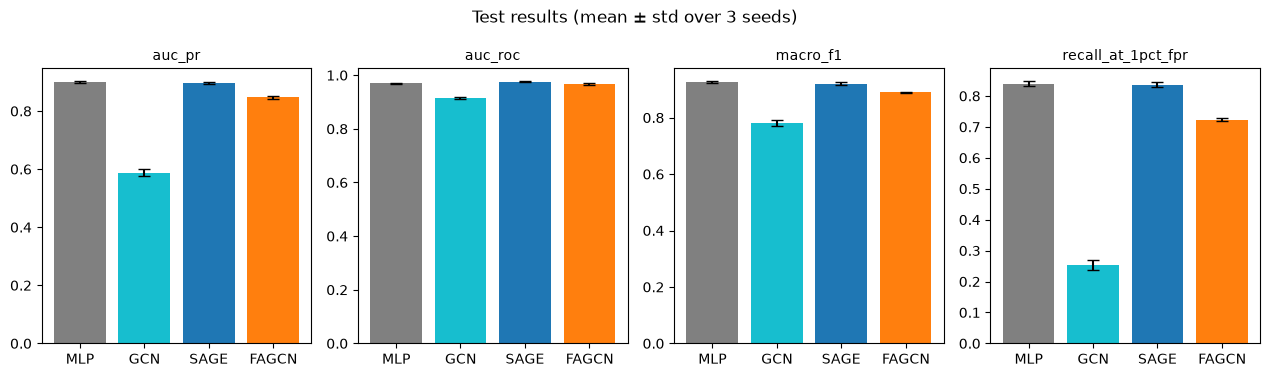

In [13]:
def plot_metric_bars(means, stds, metrics, title, save_path):
    """One bar chart per metric with error bars for the spread over seeds."""
    fig, axes = plt.subplots(1, len(metrics), figsize=(3.2 * len(metrics), 3.8))
    colours = ["grey", "tab:cyan", "tab:blue", "tab:orange"]
    for ax, metric in zip(axes, metrics):
        ax.bar(range(len(means)), means[metric], yerr=stds[metric], color=colours[:len(means)], capsize=4)
        ax.set_xticks(range(len(means)), [m.upper() if m != "graphsage" else "SAGE" for m in means.index])
        ax.set_title(metric, fontsize=10)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


plot_metric_bars(mean_table, std_table, ["auc_pr", "auc_roc", "macro_f1", "recall_at_1pct_fpr"], "Test results (mean ± std over 3 seeds)", RESULTS_DIR / "technical_metrics.png")

## 6. Stress Tests

The models trained with the first seed are tested on harder versions of the data:

| Stress test | What changes | Business meaning |
|---|---|---|
| `camouflage` | Every link between a test-set fraudster and another fraudster is rewired to a random genuine user (everyone keeps the same number of links) | Fraud rings hide their links to each other and interact with real accounts to look normal |
| `feature_noise` | Gaussian noise added to every user's features | Noisy or incomplete activity logs |
| `few_labels` | Models retrained with only 10% of the training labels | Few moderator-confirmed cases, e.g. a new product category |

In [14]:
def add_camouflage(adjacency, fraud_nodes, genuine_nodes, seed):
    """Rewire every link between a given fraudster and another fraudster to a random genuine user."""
    upper = sp.triu(adjacency, k=1).tocoo()
    rows, cols = upper.row.copy(), upper.col.copy()
    is_target = np.zeros(adjacency.shape[0], dtype=bool)
    is_target[fraud_nodes] = True
    fraud_link = (labels[rows] == 1) & (labels[cols] == 1) & (is_target[rows] | is_target[cols])

    kept_end = np.where(is_target[rows], rows, cols)
    rows[fraud_link] = kept_end[fraud_link]
    cols[fraud_link] = np.random.default_rng(seed).choice(genuine_nodes, size=fraud_link.sum())

    rewired = sp.coo_matrix((np.ones(len(rows)), (rows, cols)), shape=adjacency.shape)
    rewired = (rewired + rewired.T).tocsr()
    rewired.data[:] = 1.0
    return rewired, int(fraud_link.sum())


test_fraudsters = test_idx[labels[test_idx] == 1]
genuine_users = np.arange(3305, len(labels))[labels[3305:] == 0]
camouflaged_adjacency, rewired_links = add_camouflage(relations["all"], test_fraudsters, genuine_users, SPLIT_SEED)
camouflage_graph = build_graph(camouflaged_adjacency, DEVICE)
print(f"Rewired fraud-to-fraud links: {rewired_links:,}")

noise_generator = torch.Generator().manual_seed(SPLIT_SEED)
noisy_x = x + FEATURE_NOISE_STD * torch.randn(x.shape, generator=noise_generator).to(DEVICE)

few_labels_train, _ = train_test_split(train_idx, train_size=FEW_LABELS_SHARE, stratify=labels[train_idx], random_state=SPLIT_SEED)
print(f"Few-labels training users: {len(few_labels_train)} ({labels[few_labels_train].sum()} fraudsters)")

Rewired fraud-to-fraud links: 5,292
Few-labels training users: 345 (33 fraudsters)


In [15]:
stress_rows = []
for model_name in MODELS:
    model = trained_models[model_name]
    conditions = {
        "clean": predict(model, x, graph),
        "camouflage": predict(model, x, camouflage_graph),
        "feature_noise": predict(model, noisy_x, graph),
    }
    few_label_model, _ = train_model(model_name, few_labels_train, TRAINING_SEEDS[0])
    conditions["few_labels"] = predict(few_label_model, x, graph)

    for condition, scores in conditions.items():
        result = evaluate(scores, thresholds[model_name], test_idx)
        stress_rows.append({"model": model_name, "condition": condition, **result})

stress_results = pd.DataFrame(stress_rows)
stress_auc_pr = stress_results.pivot(index="model", columns="condition", values="auc_pr").reindex(MODELS)
stress_auc_pr = stress_auc_pr[["clean", "camouflage", "feature_noise", "few_labels"]]
stress_auc_pr.rename(index=MODEL_LABELS).round(3)

condition,clean,camouflage,feature_noise,few_labels
model,,,,
Baseline: MLP,0.900,0.900,0.818,0.839
System A: GCN,0.590,0.575,0.593,0.521
System A: GraphSAGE,0.896,0.894,0.825,0.843
System B: FAGCN,0.842,0.805,0.824,0.793


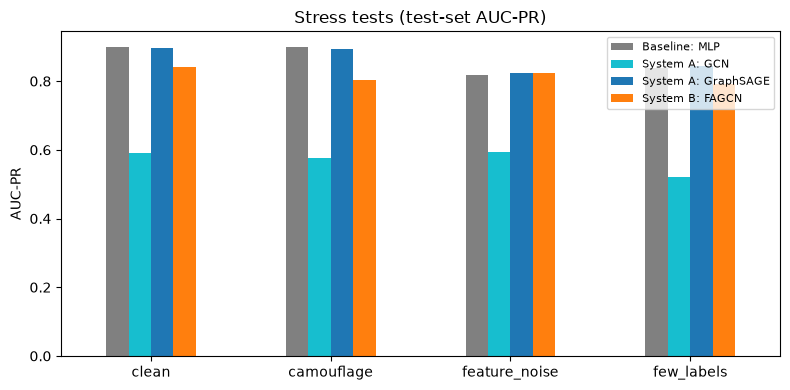

In [16]:
ax = stress_auc_pr.rename(index=MODEL_LABELS).T.plot(kind="bar", figsize=(8, 4), color=["grey", "tab:cyan", "tab:blue", "tab:orange"])
ax.set_ylabel("AUC-PR")
ax.set_xlabel("")
ax.set_title("Stress tests (test-set AUC-PR)")
ax.tick_params(axis="x", rotation=0)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "stress_tests.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Fairness and Trust

### 7.1 Performance by user activity

Users with few links (new or quiet accounts) give a graph model little to work with, and users with many links may be over-smoothed. A fair model should not wrongly flag one group of genuine users much more often than another. Test users are split into three equal-sized groups by the number of links.

In [17]:
degree = graph["degree"]
degree_groups = pd.qcut(degree[test_idx], 3, labels=["low", "medium", "high"])

fairness_rows = []
for model_name in MODELS:
    scores = test_scores[model_name]
    for group in ["low", "medium", "high"]:
        nodes = test_idx[degree_groups == group]
        flagged = scores[nodes] >= thresholds[model_name]
        genuine = labels[nodes] == 0
        fraud = labels[nodes] == 1
        fairness_rows.append({
            "model": model_name,
            "degree_group": group,
            "users": len(nodes),
            "fraud_share": fraud.mean(),
            "auc_pr": average_precision_score(labels[nodes], scores[nodes]),
            "recall": flagged[fraud].mean(),
            "false_positive_rate": flagged[genuine].mean(),
        })

fairness = pd.DataFrame(fairness_rows).round(3)
fairness.pivot(index="model", columns="degree_group", values=["auc_pr", "false_positive_rate"]).reindex(MODELS)

auc_pr               false_positive_rate              
degree_group   high    low medium                high    low medium
model                                                              
mlp           0.627  0.947  0.845               0.001  0.016  0.010
gcn           0.348  0.665  0.421               0.001  0.093  0.041
graphsage     0.613  0.946  0.834               0.003  0.030  0.019
fagcn         0.480  0.905  0.778               0.001  0.016  0.009

### 7.2 Calibration

Moderators will read the fraud probability as a confidence level. A calibrated model that says 0.8 should be right about 80% of the time. The weighted loss pushes probabilities up, so some miscalibration is expected.

* `brier_score`: mean squared error of the probabilities (lower is better).
* `ece`: expected calibration error over 10 bins (lower is better).

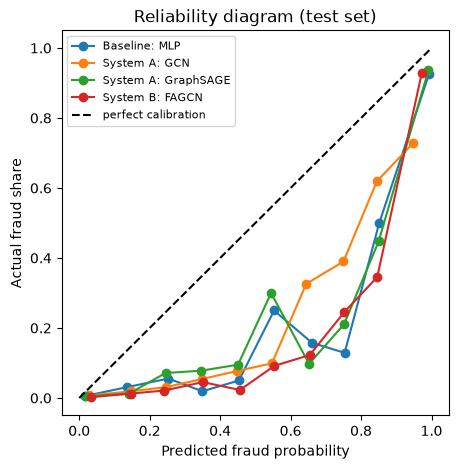

,brier_score,ece
Baseline: MLP,0.032,0.049
System A: GCN,0.099,0.157
System A: GraphSAGE,0.034,0.056
System B: FAGCN,0.077,0.143


In [18]:
def expected_calibration_error(true_labels, probabilities, bins=10):
    """Average gap between predicted probability and actual fraud rate, weighted by bin size."""
    edges = np.linspace(0, 1, bins + 1)
    bin_ids = np.clip(np.digitize(probabilities, edges) - 1, 0, bins - 1)
    error = 0
    for b in range(bins):
        in_bin = bin_ids == b
        if in_bin.any():
            error += in_bin.mean() * abs(probabilities[in_bin].mean() - true_labels[in_bin].mean())
    return error


calibration = pd.DataFrame({
    model_name: {
        "brier_score": brier_score_loss(labels[test_idx], test_scores[model_name][test_idx]),
        "ece": expected_calibration_error(labels[test_idx], test_scores[model_name][test_idx]),
    }
    for model_name in MODELS
}).T.round(3)

fig, ax = plt.subplots(figsize=(5, 5))
for model_name in MODELS:
    probabilities = test_scores[model_name][test_idx]
    bins = np.clip((probabilities * 10).astype(int), 0, 9)
    frame = pd.DataFrame({"bin": bins, "probability": probabilities, "fraud": labels[test_idx]})
    curve = frame.groupby("bin")[["probability", "fraud"]].mean()
    ax.plot(curve["probability"], curve["fraud"], marker="o", label=MODEL_LABELS[model_name])
ax.plot([0, 1], [0, 1], "k--", label="perfect calibration")
ax.set_xlabel("Predicted fraud probability")
ax.set_ylabel("Actual fraud share")
ax.legend(fontsize=8)
ax.set_title("Reliability diagram (test set)")
plt.savefig(RESULTS_DIR / "calibration.png", dpi=150, bbox_inches="tight")
plt.show()

calibration.rename(index=MODEL_LABELS)

### 7.3 Explainability: which features drive the flags

A moderator who suspends an account has to be able to say why. Permutation importance measures how much each model relies on each of the 25 account features: one feature is shuffled across all users, so linked accounts also see the shuffled values, and the drop in test AUC-PR shows how much the model needed that feature. Results use the seed-0 models and average three shuffles per feature.

The data file does not publish the feature names, so the features are numbered as they appear in it; they describe each user's reviewing behaviour. If the GNNs rely on the same top features as the MLP, the graph adds little beyond those features. This is a global view: explaining one particular flag would need a local method such as gradient saliency for that account.

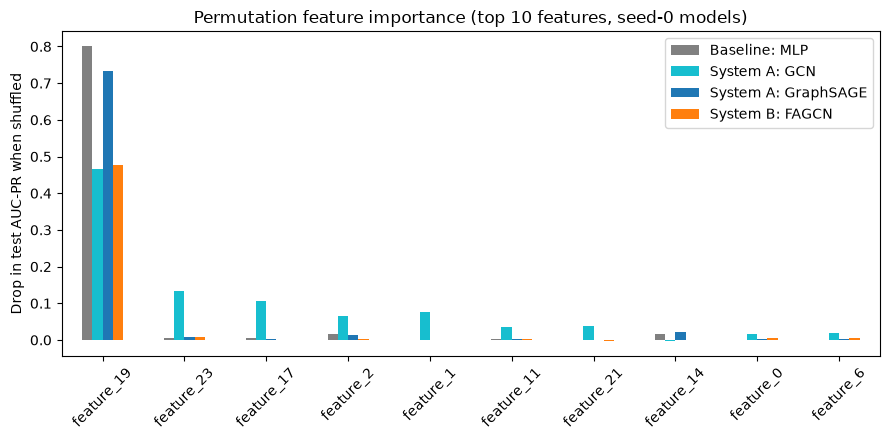

,top_features,share_of_drop_in_top
Baseline: MLP,"feature_19, feature_14, feature_2, feature_22,...",0.95
System A: GCN,"feature_19, feature_23, feature_17, feature_1,...",0.78
System A: GraphSAGE,"feature_19, feature_14, feature_13, feature_2,...",0.94
System B: FAGCN,"feature_19, feature_23, feature_6, feature_0, ...",0.99


In [19]:
IMPORTANCE_REPEATS = 3


def permutation_importance(model, x, graph, nodes, repeats, seed):
    """Drop in test AUC-PR when one feature is shuffled across all users, averaged over several shuffles."""
    generator = torch.Generator().manual_seed(seed)
    base_score = average_precision_score(labels[nodes], predict(model, x, graph)[nodes])
    drops = []
    for feature in range(x.shape[1]):
        feature_drops = []
        for _ in range(repeats):
            order = torch.randperm(x.shape[0], generator=generator).to(x.device)
            shuffled = x.clone()
            shuffled[:, feature] = x[order, feature]
            score = average_precision_score(labels[nodes], predict(model, shuffled, graph)[nodes])
            feature_drops.append(base_score - score)
        drops.append(np.mean(feature_drops))
    return np.array(drops)


def top_features_summary(importance, top_n=5):
    """Each model's most important features and the share of its total AUC-PR drop they explain."""
    rows = {}
    for model_name in importance.columns:
        ranked = importance[model_name].sort_values(ascending=False)
        rows[model_name] = {
            "top_features": ", ".join(ranked.index[:top_n]),
            "share_of_drop_in_top": round(ranked[:top_n].sum() / ranked.clip(lower=0).sum(), 2),
        }
    return pd.DataFrame(rows).T


importance = pd.DataFrame(
    {model_name: permutation_importance(trained_models[model_name], x, graph, test_idx, IMPORTANCE_REPEATS, SPLIT_SEED) for model_name in MODELS},
    index=[f"feature_{i}" for i in range(x.shape[1])],
).round(4)
top_ten = importance.loc[importance.mean(axis=1).sort_values(ascending=False).index[:10]]

fig, ax = plt.subplots(figsize=(9, 4.5))
top_ten.rename(columns=MODEL_LABELS).plot(kind="bar", ax=ax, color=["grey", "tab:cyan", "tab:blue", "tab:orange"])
ax.set_ylabel("Drop in test AUC-PR when shuffled")
ax.set_title("Permutation feature importance (top 10 features, seed-0 models)")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

feature_summary = top_features_summary(importance)
feature_summary.rename(index=MODEL_LABELS)

## 8. Business and Environmental Cost

| Assumption | Value | Meaning |
|---|---|---|
| `COST_MISSED_FRAUDSTER` | AUD 150 | Harm from one fake reviewer left active (misled buyers, refunds, seller complaints) |
| `COST_WRONG_SUSPENSION` | AUD 40 | One genuine user wrongly suspended (support ticket, lost trust and sales) |
| `COST_MODERATOR_REVIEW` | AUD 4 | A moderator checking one flagged account |
| `ACCOUNTS_PER_MONTH` | 100,000 | Accounts screened each month |

For each model the threshold that gives the lowest cost on the **validation** set is chosen, then the cost is measured on the test set. "No model" means nobody is flagged and every fraudster stays active.

In [20]:
COST_MISSED_FRAUDSTER = 150
COST_WRONG_SUSPENSION = 40
COST_MODERATOR_REVIEW = 4
ACCOUNTS_PER_MONTH = 100_000
POWER_KW = {"cuda": 0.115, "cpu": 0.065}
ELECTRICITY_AUD_PER_KWH = 0.30


def business_cost(true_labels, flagged):
    """Total cost of missed fraudsters, wrong suspensions and moderator reviews."""
    missed = ((true_labels == 1) & ~flagged).sum()
    wrong = ((true_labels == 0) & flagged).sum()
    return missed * COST_MISSED_FRAUDSTER + wrong * COST_WRONG_SUSPENSION + flagged.sum() * COST_MODERATOR_REVIEW


def cheapest_threshold(true_labels, scores):
    """Threshold with the lowest business cost (chosen on the validation set)."""
    candidates = np.quantile(scores, np.linspace(0.5, 0.999, 300))
    costs = [business_cost(true_labels, scores >= t) for t in candidates]
    return candidates[int(np.argmin(costs))]


no_model_cost = business_cost(labels[test_idx], np.zeros(len(test_idx), dtype=bool))
cost_rows = [{"model": "no_model", "aud_per_month": no_model_cost / len(test_idx) * ACCOUNTS_PER_MONTH}]

for model_name in MODELS:
    scores = test_scores[model_name]
    threshold = cheapest_threshold(labels[val_idx], scores[val_idx])
    flagged = scores[test_idx] >= threshold
    cost = business_cost(labels[test_idx], flagged)
    train_seconds = runs[runs["model"] == model_name]["train_seconds"].mean()
    cost_rows.append({
        "model": model_name,
        "flagged_share": flagged.mean(),
        "aud_per_month": cost / len(test_idx) * ACCOUNTS_PER_MONTH,
        "training_wh": train_seconds / 3600 * POWER_KW[DEVICE] * 1000,
        "training_aud_electricity": train_seconds / 3600 * POWER_KW[DEVICE] * ELECTRICITY_AUD_PER_KWH,
    })

cost_table = pd.DataFrame(cost_rows).set_index("model")
cost_table["saving_vs_no_model_aud"] = cost_table.loc["no_model", "aud_per_month"] - cost_table["aud_per_month"]
cost_table.round(2)

,aud_per_month,flagged_share,training_wh,training_aud_electricity,saving_vs_no_model_aud
model,,,,,
no_model,1427951.39,NaN,NaN,NaN,0.00
mlp,281192.13,0.09,0.02,0.0,1146759.26
gcn,704050.93,0.14,0.60,0.0,723900.46
graphsage,330497.69,0.11,0.14,0.0,1097453.70
fagcn,463078.70,0.09,1.99,0.0,964872.69


## 9. Self-Evaluation (User Feedback)

The marketplace's users of this system are moderators, so the self-evaluation is done from a moderator's point of view after looking at the results above. The cell creates `self_evaluation.csv` once (it is never overwritten). Score each model 1-5:

| Column | Question |
|---|---|
| `flags_are_useful` | Would the flagged accounts be worth a moderator's time? (precision at the chosen threshold, examples) |
| `explainable` | Can I explain to a seller why their account was flagged? |
| `robust` | Does it keep working under the stress tests? |
| `fair` | Are genuine low-activity users treated as well as others? |
| `easy_to_run` | Training time, tuning effort, hardware needed |

In [21]:
FEEDBACK_COLUMNS = ["flags_are_useful", "explainable", "robust", "fair", "easy_to_run"]

if not SELF_EVALUATION_PATH.exists():
    template = pd.DataFrame({"model": MODELS})
    for column in FEEDBACK_COLUMNS + ["notes"]:
        template[column] = ""
    save_table(template, SELF_EVALUATION_PATH)
    print(f"Template created: {SELF_EVALUATION_PATH}")

self_evaluation = pd.read_csv(SELF_EVALUATION_PATH).set_index("model")
if self_evaluation[FEEDBACK_COLUMNS].isna().all().all():
    print("No scores yet. Fill in self_evaluation.csv and run this cell again.")
else:
    self_evaluation["average"] = self_evaluation[FEEDBACK_COLUMNS].mean(axis=1).round(2)
    display(self_evaluation.rename(index=MODEL_LABELS))

,flags_are_useful,explainable,robust,fair,easy_to_run,notes,average
model,,,,,,,
Baseline: MLP,5,4,4,3,5,"AUC-PR 0.899, recall 0.84 at 1% FPR; flags res...",4.2
System A: GCN,2,2,2,2,3,"AUC-PR 0.589, recall only 0.27 at 1% FPR, so m...",2.2
System A: GraphSAGE,5,3,4,3,4,"AUC-PR 0.896, recall 0.84 at 1% FPR, level wit...",3.8
System B: FAGCN,4,2,3,2,2,"AUC-PR 0.847, recall 0.72 at 1% FPR, clearly b...",2.6


## 10. Saving Results

In [22]:
save_table(split_table, RESULTS_DIR / "splits.csv")
save_table(homophily_table.reset_index(names="relation"), RESULTS_DIR / "homophily.csv")
save_table(summary.reset_index(), RESULTS_DIR / "technical_summary.csv")
save_table(mean_table.reset_index(), RESULTS_DIR / "technical_means.csv")
save_table(stress_results, RESULTS_DIR / "stress_results.csv")
save_table(fairness, RESULTS_DIR / "fairness_by_degree.csv")
save_table(calibration.reset_index(names="model"), RESULTS_DIR / "calibration.csv")
save_table(cost_table.reset_index(), RESULTS_DIR / "business_cost.csv")
save_table(importance.reset_index(names="feature"), RESULTS_DIR / "feature_importance.csv")
save_table(feature_summary.reset_index(names="model"), RESULTS_DIR / "feature_importance_summary.csv")

for path in sorted(RESULTS_DIR.iterdir()):
    print(path.name)

business_cost.csv
calibration.csv
calibration.png
environment.json
fairness_by_degree.csv
feature_importance.csv
feature_importance.png
feature_importance_summary.csv
homophily.csv
splits.csv
stress_results.csv
stress_tests.png
technical_means.csv
technical_metrics.png
technical_summary.csv
training_runs.csv
